# NLP Lab Assignment: Q1 to Q6
Text preprocessing, stemming/lemmatization, BoW & TF-IDF, similarity, sentiment analysis and a simple text generator.

In [2]:
# Run once (Colab / fresh environment)
!pip install -q nltk scikit-learn textblob vaderSentiment wordcloud matplotlib pandas tensorflow

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4", "vader_lexicon"]:
    nltk.download(pkg, quiet=True)

---
# Q1. Basic text preprocessing
**Favourite topic: Cricket** (paragraph used for Q1 and Q2)

In [3]:
text = ("Cricket is more than a sport in India; it is a shared emotion that brings millions of people together. "
        "I still remember watching the 2011 World Cup final with my family, cheering for every boundary and wicket. "
        "The game rewards patience, strategy, and teamwork, whether it is a five-day Test match or a fast T20 clash. "
        "Players like Virat Kohli and Sachin Tendulkar have inspired generations of young fans to pick up a bat and chase their dreams. "
        "Every evening, children in street corners play with tennis balls and makeshift stumps, imitating their heroes. "
        "Cricket teaches us that victory is sweet, but resilience after defeat is even more valuable.")
print(text)

Cricket is more than a sport in India; it is a shared emotion that brings millions of people together. I still remember watching the 2011 World Cup final with my family, cheering for every boundary and wicket. The game rewards patience, strategy, and teamwork, whether it is a five-day Test match or a fast T20 clash. Players like Virat Kohli and Sachin Tendulkar have inspired generations of young fans to pick up a bat and chase their dreams. Every evening, children in street corners play with tennis balls and makeshift stumps, imitating their heroes. Cricket teaches us that victory is sweet, but resilience after defeat is even more valuable.


### 1. Lowercase and remove punctuation using `re`

In [4]:
import re

lower_text = text.lower()
clean_text = re.sub(r"[^\w\s]", "", lower_text)   # remove punctuation
print(clean_text)

cricket is more than a sport in india it is a shared emotion that brings millions of people together i still remember watching the 2011 world cup final with my family cheering for every boundary and wicket the game rewards patience strategy and teamwork whether it is a fiveday test match or a fast t20 clash players like virat kohli and sachin tendulkar have inspired generations of young fans to pick up a bat and chase their dreams every evening children in street corners play with tennis balls and makeshift stumps imitating their heroes cricket teaches us that victory is sweet but resilience after defeat is even more valuable


### 2. Tokenize into sentences and words

In [5]:
from nltk.tokenize import sent_tokenize, word_tokenize

sentences = sent_tokenize(text)
print("Number of sentences:", len(sentences))
for i, s in enumerate(sentences, 1):
    print(i, s)

words = word_tokenize(clean_text)
print("\nNumber of words:", len(words))
print(words)

Number of sentences: 6
1 Cricket is more than a sport in India; it is a shared emotion that brings millions of people together.
2 I still remember watching the 2011 World Cup final with my family, cheering for every boundary and wicket.
3 The game rewards patience, strategy, and teamwork, whether it is a five-day Test match or a fast T20 clash.
4 Players like Virat Kohli and Sachin Tendulkar have inspired generations of young fans to pick up a bat and chase their dreams.
5 Every evening, children in street corners play with tennis balls and makeshift stumps, imitating their heroes.
6 Cricket teaches us that victory is sweet, but resilience after defeat is even more valuable.

Number of words: 109
['cricket', 'is', 'more', 'than', 'a', 'sport', 'in', 'india', 'it', 'is', 'a', 'shared', 'emotion', 'that', 'brings', 'millions', 'of', 'people', 'together', 'i', 'still', 'remember', 'watching', 'the', '2011', 'world', 'cup', 'final', 'with', 'my', 'family', 'cheering', 'for', 'every', 'boun

### 3. `split()` vs `word_tokenize()`

In [6]:
sample = "Cricket isn't just a game; it's emotion, isn't it? Yes - it is!"

print("split()        :", sample.split())
print("word_tokenize():", word_tokenize(sample))

split()        : ['Cricket', "isn't", 'just', 'a', 'game;', "it's", 'emotion,', "isn't", 'it?', 'Yes', '-', 'it', 'is!']
word_tokenize(): ['Cricket', 'is', "n't", 'just', 'a', 'game', ';', 'it', "'s", 'emotion', ',', 'is', "n't", 'it', '?', 'Yes', '-', 'it', 'is', '!']


**Difference**
- `split()` only cuts on whitespace, so punctuation stays glued to words (`game;`, `it?`, `it!`) and contractions are not handled.
- `word_tokenize()` is language aware: it separates punctuation into its own tokens and splits contractions (`isn't` -> `is`, `n't`; `it's` -> `it`, `'s`).
- `split()` is faster and fine for already-clean text; `word_tokenize()` is better for raw text.

### 4. Remove stopwords

In [7]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))
filtered_words = [w for w in words if w not in stop_words]

print("Before:", len(words), "words | After:", len(filtered_words), "words")
print(filtered_words)

Before: 109 words | After: 68 words
['cricket', 'sport', 'india', 'shared', 'emotion', 'brings', 'millions', 'people', 'together', 'still', 'remember', 'watching', '2011', 'world', 'cup', 'final', 'family', 'cheering', 'every', 'boundary', 'wicket', 'game', 'rewards', 'patience', 'strategy', 'teamwork', 'whether', 'fiveday', 'test', 'match', 'fast', 't20', 'clash', 'players', 'like', 'virat', 'kohli', 'sachin', 'tendulkar', 'inspired', 'generations', 'young', 'fans', 'pick', 'bat', 'chase', 'dreams', 'every', 'evening', 'children', 'street', 'corners', 'play', 'tennis', 'balls', 'makeshift', 'stumps', 'imitating', 'heroes', 'cricket', 'teaches', 'us', 'victory', 'sweet', 'resilience', 'defeat', 'even', 'valuable']


### 5. Word frequency distribution (excluding stopwords)

[('cricket', 2), ('every', 2), ('sport', 1), ('india', 1), ('shared', 1), ('emotion', 1), ('brings', 1), ('millions', 1), ('people', 1), ('together', 1)]


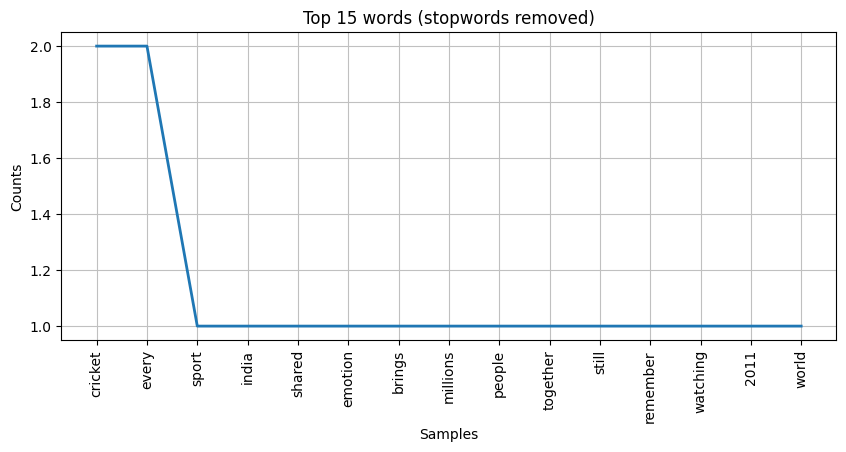

In [8]:
from nltk import FreqDist
import matplotlib.pyplot as plt

fdist = FreqDist(filtered_words)
print(fdist.most_common(10))

plt.figure(figsize=(10, 4))
fdist.plot(15, title="Top 15 words (stopwords removed)")
plt.show()

---
# Q2. Regex extraction, stemming and lemmatization (same paragraph)

### 1. Extract alphabet-only words with `re.findall()`

In [9]:
alpha_words = re.findall(r"[a-zA-Z]+", text.lower())
print(len(alpha_words), alpha_words)

109 ['cricket', 'is', 'more', 'than', 'a', 'sport', 'in', 'india', 'it', 'is', 'a', 'shared', 'emotion', 'that', 'brings', 'millions', 'of', 'people', 'together', 'i', 'still', 'remember', 'watching', 'the', 'world', 'cup', 'final', 'with', 'my', 'family', 'cheering', 'for', 'every', 'boundary', 'and', 'wicket', 'the', 'game', 'rewards', 'patience', 'strategy', 'and', 'teamwork', 'whether', 'it', 'is', 'a', 'five', 'day', 'test', 'match', 'or', 'a', 'fast', 't', 'clash', 'players', 'like', 'virat', 'kohli', 'and', 'sachin', 'tendulkar', 'have', 'inspired', 'generations', 'of', 'young', 'fans', 'to', 'pick', 'up', 'a', 'bat', 'and', 'chase', 'their', 'dreams', 'every', 'evening', 'children', 'in', 'street', 'corners', 'play', 'with', 'tennis', 'balls', 'and', 'makeshift', 'stumps', 'imitating', 'their', 'heroes', 'cricket', 'teaches', 'us', 'that', 'victory', 'is', 'sweet', 'but', 'resilience', 'after', 'defeat', 'is', 'even', 'more', 'valuable']


### 2. Remove stopwords

In [10]:
alpha_filtered = [w for w in alpha_words if w not in stop_words]
print(len(alpha_filtered), alpha_filtered)

67 ['cricket', 'sport', 'india', 'shared', 'emotion', 'brings', 'millions', 'people', 'together', 'still', 'remember', 'watching', 'world', 'cup', 'final', 'family', 'cheering', 'every', 'boundary', 'wicket', 'game', 'rewards', 'patience', 'strategy', 'teamwork', 'whether', 'five', 'day', 'test', 'match', 'fast', 'clash', 'players', 'like', 'virat', 'kohli', 'sachin', 'tendulkar', 'inspired', 'generations', 'young', 'fans', 'pick', 'bat', 'chase', 'dreams', 'every', 'evening', 'children', 'street', 'corners', 'play', 'tennis', 'balls', 'makeshift', 'stumps', 'imitating', 'heroes', 'cricket', 'teaches', 'us', 'victory', 'sweet', 'resilience', 'defeat', 'even', 'valuable']


### 3. Stemming (PorterStemmer)

In [11]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()
stemmed = [stemmer.stem(w) for w in alpha_filtered]
print(stemmed)

['cricket', 'sport', 'india', 'share', 'emot', 'bring', 'million', 'peopl', 'togeth', 'still', 'rememb', 'watch', 'world', 'cup', 'final', 'famili', 'cheer', 'everi', 'boundari', 'wicket', 'game', 'reward', 'patienc', 'strategi', 'teamwork', 'whether', 'five', 'day', 'test', 'match', 'fast', 'clash', 'player', 'like', 'virat', 'kohli', 'sachin', 'tendulkar', 'inspir', 'gener', 'young', 'fan', 'pick', 'bat', 'chase', 'dream', 'everi', 'even', 'children', 'street', 'corner', 'play', 'tenni', 'ball', 'makeshift', 'stump', 'imit', 'hero', 'cricket', 'teach', 'us', 'victori', 'sweet', 'resili', 'defeat', 'even', 'valuabl']


### 4. Lemmatization (WordNetLemmatizer)

In [12]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()
lemmatized_noun = [lemmatizer.lemmatize(w) for w in alpha_filtered]               # default POS = noun
lemmatized_verb = [lemmatizer.lemmatize(w, pos="v") for w in alpha_filtered]      # treat as verbs
print("Noun :", lemmatized_noun)
print("Verb :", lemmatized_verb)

Noun : ['cricket', 'sport', 'india', 'shared', 'emotion', 'brings', 'million', 'people', 'together', 'still', 'remember', 'watching', 'world', 'cup', 'final', 'family', 'cheering', 'every', 'boundary', 'wicket', 'game', 'reward', 'patience', 'strategy', 'teamwork', 'whether', 'five', 'day', 'test', 'match', 'fast', 'clash', 'player', 'like', 'virat', 'kohli', 'sachin', 'tendulkar', 'inspired', 'generation', 'young', 'fan', 'pick', 'bat', 'chase', 'dream', 'every', 'evening', 'child', 'street', 'corner', 'play', 'tennis', 'ball', 'makeshift', 'stump', 'imitating', 'hero', 'cricket', 'teach', 'u', 'victory', 'sweet', 'resilience', 'defeat', 'even', 'valuable']
Verb : ['cricket', 'sport', 'india', 'share', 'emotion', 'bring', 'millions', 'people', 'together', 'still', 'remember', 'watch', 'world', 'cup', 'final', 'family', 'cheer', 'every', 'boundary', 'wicket', 'game', 'reward', 'patience', 'strategy', 'teamwork', 'whether', 'five', 'day', 'test', 'match', 'fast', 'clash', 'players', 'li

### 5. Compare stemmed vs lemmatized output

In [13]:
import pandas as pd

comparison = pd.DataFrame({
    "original": alpha_filtered,
    "stemmed": stemmed,
    "lemma (noun)": lemmatized_noun,
    "lemma (verb)": lemmatized_verb,
})
comparison[comparison["original"] != comparison["stemmed"]].drop_duplicates().reset_index(drop=True)

,original,stemmed,lemma (noun),lemma (verb)
0,shared,share,shared,share
1,emotion,emot,emotion,emotion
2,brings,bring,brings,bring
3,millions,million,million,millions
4,people,peopl,people,people
5,together,togeth,together,together
6,remember,rememb,remember,remember
7,watching,watch,watching,watch
8,family,famili,family,family
9,cheering,cheer,cheering,cheer


**When to prefer which?**

| | Stemming (Porter) | Lemmatization (WordNet) |
|---|---|---|
| How it works | Chops suffixes using rules | Dictionary lookup, returns a real word |
| Output | May be non-words (`emot`, `strategi`, `valuabl`) | Valid words (`emotion`, `strategy`) |
| Speed | Very fast | Slower |
| Accuracy | Lower, can over-stem | Higher, uses POS context |

- **Prefer stemming** for large-scale search/indexing, spam filters or quick baselines where speed matters and readable output does not.
- **Prefer lemmatization** for chatbots, sentiment analysis, QA or anything where meaning and readable words matter.

---
# Q3. Bag of Words and TF-IDF on 3 short texts

In [14]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd

texts = [
    "India wins the thrilling cricket match against Australia in the final over",
    "The new smartphone offers an amazing camera and a long lasting battery",
    "Heavy rain floods several streets in the city causing traffic delays",
]
labels = ["Text 1 (sports)", "Text 2 (product)", "Text 3 (news)"]

### 1. Bag of Words (CountVectorizer)

In [15]:
cv = CountVectorizer(stop_words="english")
bow = cv.fit_transform(texts)
bow_df = pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out(), index=labels)
bow_df

,amazing,australia,battery,camera,causing,city,cricket,delays,final,floods,...,long,match,new,offers,rain,smartphone,streets,thrilling,traffic,wins
Text 1 (sports),0,1,0,0,0,0,1,0,1,0,...,0,1,0,0,0,0,0,1,0,1
Text 2 (product),1,0,1,1,0,0,0,0,0,0,...,1,0,1,1,0,1,0,0,0,0
Text 3 (news),0,0,0,0,1,1,0,1,0,1,...,0,0,0,0,1,0,1,0,1,0


### 2. TF-IDF (TfidfVectorizer)

In [16]:
tfidf = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf.fit_transform(texts)
tfidf_df = pd.DataFrame(tfidf_matrix.toarray().round(3), columns=tfidf.get_feature_names_out(), index=labels)
tfidf_df

,amazing,australia,battery,camera,causing,city,cricket,delays,final,floods,...,long,match,new,offers,rain,smartphone,streets,thrilling,traffic,wins
Text 1 (sports),0.000,0.378,0.000,0.000,0.000,0.000,0.378,0.000,0.378,0.000,...,0.000,0.378,0.000,0.000,0.000,0.000,0.000,0.378,0.000,0.378
Text 2 (product),0.354,0.000,0.354,0.354,0.000,0.000,0.000,0.000,0.000,0.000,...,0.354,0.000,0.354,0.354,0.000,0.354,0.000,0.000,0.000,0.000
Text 3 (news),0.000,0.000,0.000,0.000,0.354,0.354,0.000,0.354,0.000,0.354,...,0.000,0.000,0.000,0.000,0.354,0.000,0.354,0.000,0.354,0.000


### 3. Top 3 keywords per text using TF-IDF

In [17]:
import numpy as np

features = tfidf.get_feature_names_out()
for i, label in enumerate(labels):
    row = tfidf_matrix[i].toarray().flatten()
    top3 = np.argsort(row)[::-1][:3]
    print(label)
    for idx in top3:
        print(f"   {features[idx]:<12} {row[idx]:.3f}")

Text 1 (sports)
   wins         0.378
   thrilling    0.378
   australia    0.378
Text 2 (product)
   smartphone   0.354
   offers       0.354
   amazing      0.354
Text 3 (news)
   traffic      0.354
   rain         0.354
   streets      0.354


**Interpretation**
- Bag of Words only counts occurrences, so every word that appears once looks equally important.
- TF-IDF weights a word higher when it is frequent in a document but rare across the other documents. The top keywords therefore capture each text's topic (for example *cricket, match, final* for the sports text, *smartphone, camera, battery* for the product text, *rain, floods, traffic* for the news text).
- Words that appear in more than one text get a lower IDF and drop in ranking.

---
# Q4. Jaccard vs Cosine similarity (AI vs Blockchain)

In [18]:
text_ai = ("Artificial intelligence enables machines to learn from data and make decisions. "
           "Machine learning models are trained on large datasets to recognize patterns. "
           "AI is used in healthcare, finance and self driving cars. "
           "It can automate tasks and improve the speed of data analysis.")

text_bc = ("Blockchain is a distributed ledger that records transactions securely. "
           "Each block is linked to the previous block using cryptographic hashes. "
           "It is used in cryptocurrency, finance and supply chains. "
           "Data on a blockchain is transparent and very hard to change.")

### 1. Preprocess and tokenize

In [19]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import re

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess(t):
    t = re.sub(r"[^a-z\s]", "", t.lower())
    tokens = word_tokenize(t)
    return [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words]

tokens_ai = preprocess(text_ai)
tokens_bc = preprocess(text_bc)
print("AI        :", tokens_ai)
print("Blockchain:", tokens_bc)

AI        : ['artificial', 'intelligence', 'enables', 'machine', 'learn', 'data', 'make', 'decision', 'machine', 'learning', 'model', 'trained', 'large', 'datasets', 'recognize', 'pattern', 'ai', 'used', 'healthcare', 'finance', 'self', 'driving', 'car', 'automate', 'task', 'improve', 'speed', 'data', 'analysis']
Blockchain: ['blockchain', 'distributed', 'ledger', 'record', 'transaction', 'securely', 'block', 'linked', 'previous', 'block', 'using', 'cryptographic', 'hash', 'used', 'cryptocurrency', 'finance', 'supply', 'chain', 'data', 'blockchain', 'transparent', 'hard', 'change']


### 2a. Jaccard similarity (sets)

In [20]:
set_ai, set_bc = set(tokens_ai), set(tokens_bc)
intersection = set_ai & set_bc
union = set_ai | set_bc
jaccard = len(intersection) / len(union)

print("Common words:", intersection)
print("Jaccard similarity:", round(jaccard, 4))

Common words: {'used', 'finance', 'data'}
Jaccard similarity: 0.0667


### 2b. Cosine similarity (TF-IDF)

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

docs = [" ".join(tokens_ai), " ".join(tokens_bc)]
vec = TfidfVectorizer()
tfidf_vecs = vec.fit_transform(docs)
cos_sim = cosine_similarity(tfidf_vecs[0], tfidf_vecs[1])[0][0]
print("Cosine similarity:", round(cos_sim, 4))

Cosine similarity: 0.0731


### 2c. Analysis
- **Jaccard** only looks at whether words are present or absent. It ignores how often a word appears and treats every shared word equally.
- **Cosine with TF-IDF** accounts for word frequency and down-weights words common to both texts, so it reflects how similar the *content and emphasis* of the documents really are.
- Here the two texts share only a few generic words (such as *data* and *finance*) while the technical vocabulary differs, so both scores are low. Cosine/TF-IDF gives the more informative result because it shows that the overlap carries little weight, whereas Jaccard depends on the size of the vocabulary union and is sensitive to text length.
- For short texts Jaccard is a quick sanity check; for real document comparison, TF-IDF cosine is the better metric.

---
# Q5. Sentiment analysis, classification and word cloud

In [22]:
reviews = [
    "The delivery was fast and the packaging was excellent. I love this product!",
    "Absolutely terrible quality. It broke after two days and support was useless.",
    "The phone is okay. Battery is average and the camera is fine for the price.",
    "Great value for money, the screen is bright and the performance is amazing.",
    "Worst purchase ever. The app keeps crashing and I am very disappointed.",
    "Comfortable seats, friendly staff and a wonderful experience overall.",
    "The product arrived on time. It works as described.",
    "Poor service, rude staff and a long waiting time. Never coming back.",
    "Fantastic sound quality and a beautiful design. Highly recommended!",
    "Decent laptop, nothing special but it does the job.",
]

### 1. Polarity and subjectivity (TextBlob) + VADER compound score

In [23]:
from textblob import TextBlob
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import pandas as pd

sia = SentimentIntensityAnalyzer()

rows = []
for r in reviews:
    tb = TextBlob(r)
    rows.append({
        "review": r,
        "polarity": round(tb.sentiment.polarity, 3),
        "subjectivity": round(tb.sentiment.subjectivity, 3),
        "vader_compound": sia.polarity_scores(r)["compound"],
    })

df = pd.DataFrame(rows)
df

,review,polarity,subjectivity,vader_compound
0,The delivery was fast and the packaging was ex...,0.608,0.733,0.8478
1,Absolutely terrible quality. It broke after tw...,-0.750,0.600,-0.7425
2,The phone is okay. Battery is average and the ...,0.256,0.467,0.4019
3,"Great value for money, the screen is bright an...",0.700,0.817,0.9217
4,Worst purchase ever. The app keeps crashing an...,-0.988,0.988,-0.8173
5,"Comfortable seats, friendly staff and a wonder...",0.444,0.575,0.8807
6,The product arrived on time. It works as descr...,0.000,0.000,0.0000
7,"Poor service, rude staff and a long waiting ti...",-0.188,0.400,-0.7269
8,Fantastic sound quality and a beautiful design...,0.462,0.710,0.8716
9,"Decent laptop, nothing special but it does the...",0.262,0.619,-0.1603


### 2. Classify as Positive / Negative / Neutral (VADER thresholds: >= 0.05 / <= -0.05)

In [24]:
def classify(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"

df["sentiment"] = df["vader_compound"].apply(classify)
print(df["sentiment"].value_counts())
df[["review", "polarity", "subjectivity", "vader_compound", "sentiment"]]

sentiment
Positive    5
Negative    4
Neutral     1
Name: count, dtype: int64


,review,polarity,subjectivity,vader_compound,sentiment
0,The delivery was fast and the packaging was ex...,0.608,0.733,0.8478,Positive
1,Absolutely terrible quality. It broke after tw...,-0.750,0.600,-0.7425,Negative
2,The phone is okay. Battery is average and the ...,0.256,0.467,0.4019,Positive
3,"Great value for money, the screen is bright an...",0.700,0.817,0.9217,Positive
4,Worst purchase ever. The app keeps crashing an...,-0.988,0.988,-0.8173,Negative
5,"Comfortable seats, friendly staff and a wonder...",0.444,0.575,0.8807,Positive
6,The product arrived on time. It works as descr...,0.000,0.000,0.0000,Neutral
7,"Poor service, rude staff and a long waiting ti...",-0.188,0.400,-0.7269,Negative
8,Fantastic sound quality and a beautiful design...,0.462,0.710,0.8716,Positive
9,"Decent laptop, nothing special but it does the...",0.262,0.619,-0.1603,Negative


### 3. Word cloud of positive reviews

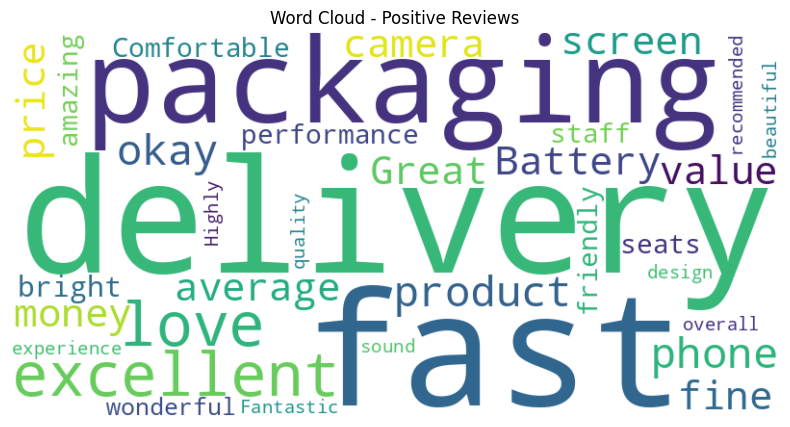

In [25]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

positive_text = " ".join(df[df["sentiment"] == "Positive"]["review"])

wc = WordCloud(width=800, height=400, background_color="white",
               stopwords=STOPWORDS, colormap="viridis").generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Positive Reviews")
plt.show()

---
# Q6. Next-word text generation with Keras (LSTM)

In [26]:
train_text = ("Cricket is a game of patience and passion. Every morning children run to the ground with a bat and a ball. "
              "They dream of hitting the winning six in the final over. The crowd cheers loudly for every boundary and wicket. "
              "A good team plays together and never gives up. Practice and discipline make a player strong. "
              "Cricket brings people together and teaches us to respect the game and our opponents. "
              "Victory feels sweet but learning from defeat makes a champion.")
print(len(train_text.split()), "words")

81 words


### 1. Tokenize with Keras `Tokenizer`

In [27]:
import numpy as np
try:
    from tensorflow.keras.preprocessing.text import Tokenizer
    from tensorflow.keras.preprocessing.sequence import pad_sequences
    from tensorflow.keras.utils import to_categorical
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Embedding, LSTM, Dense
except ImportError:
    from keras.preprocessing.text import Tokenizer
    from keras.preprocessing.sequence import pad_sequences
    from keras.utils import to_categorical
    from keras.models import Sequential
    from keras.layers import Embedding, LSTM, Dense

tokenizer = Tokenizer()
tokenizer.fit_on_texts([train_text.lower()])
total_words = len(tokenizer.word_index) + 1
print("Vocabulary size:", total_words)
print(list(tokenizer.word_index.items())[:15])

Vocabulary size: 61
[('and', 1), ('a', 2), ('the', 3), ('cricket', 4), ('game', 5), ('of', 6), ('every', 7), ('to', 8), ('together', 9), ('is', 10), ('patience', 11), ('passion', 12), ('morning', 13), ('children', 14), ('run', 15)]


### 2. Create input sequences and build the LSTM model

In [28]:
input_sequences = []
for sentence in train_text.lower().split("."):
    token_list = tokenizer.texts_to_sequences([sentence])[0]
    for i in range(2, len(token_list) + 1):
        input_sequences.append(token_list[:i])

max_len = max(len(seq) for seq in input_sequences)
input_sequences = pad_sequences(input_sequences, maxlen=max_len, padding="pre")

X = input_sequences[:, :-1]
y = to_categorical(input_sequences[:, -1], num_classes=total_words)
print("X shape:", X.shape, "| y shape:", y.shape)

model = Sequential([
    Embedding(total_words, 64),
    LSTM(100),
    Dense(total_words, activation="softmax"),
])
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.build(input_shape=(None, max_len - 1))
model.summary()

X shape: (73, 13) | y shape: (73, 61)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 13, 64)         │         3,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 100)            │        66,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 61)             │         6,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 76,065 (297.13 KB)

 Trainable params: 76,065 (297.13 KB)

 Non-trainable params: 0 (0.00 B)

### 3. Train the model

Final loss    : 0.0832
Final accuracy: 0.9863


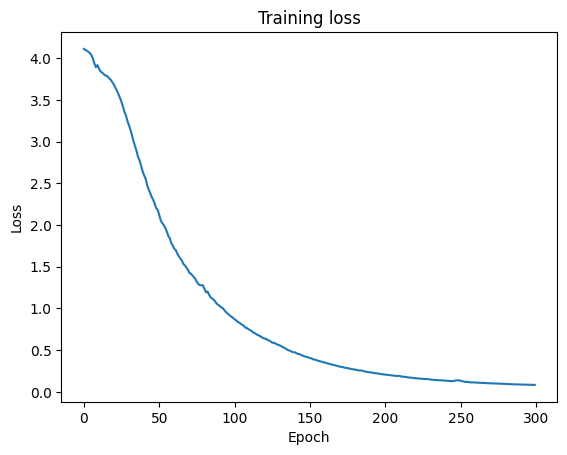

In [29]:
history = model.fit(X, y, epochs=300, verbose=0)
print("Final loss    :", round(history.history["loss"][-1], 4))
print("Final accuracy:", round(history.history["accuracy"][-1], 4))

import matplotlib.pyplot as plt
plt.plot(history.history["loss"])
plt.title("Training loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.show()

### 4. Generate new lines from seed words

In [30]:
def generate_text(seed_text, next_words=10):
    result = seed_text
    for _ in range(next_words):
        seq = tokenizer.texts_to_sequences([result.lower()])[0]
        seq = pad_sequences([seq], maxlen=max_len - 1, padding="pre")
        probs = model.predict(seq, verbose=0)[0]
        predicted_id = int(np.argmax(probs))
        word = tokenizer.index_word.get(predicted_id, "")
        if not word:
            break
        result += " " + word
    return result

for seed in ["cricket", "the crowd", "a good team"]:
    print(generate_text(seed, next_words=10))

cricket brings people together and teaches us to respect the game
the crowd cheers loudly for every boundary and wicket wicket a champion
a good team plays together and never gives up up opponents opponents opponents


**Note:** With such a tiny training set the model mostly memorises the paragraph, so generated lines closely follow the training text. A larger corpus and temperature sampling would give more varied output.